# 🔬 Skin Undertone Classification: ResNet-50 dengan Pre-processing Penajaman (Sharpening)

Notebook ini dikembangkan khusus untuk klasifikasi **Skin Undertone (Cool, Neutral, Warm)** menggunakan arsitektur **ResNet-50 (Transfer Learning & Fine-Tuning)**.

### 📌 Ringkasan Analisis Dataset (Train Set)
Berdasarkan analisis karakteristik visual pada data pelatihan:
1. **Distribusi Kelas**: Total 625 citra train (*Cool*: 173 [27.7%], *Neutral*: 255 [40.8%], *Warm*: 197 [31.5%]). Terdapat *class imbalance* di mana kelas *Neutral* lebih dominan; diatasi dengan **Weighted CrossEntropyLoss** dan **Label Smoothing**.
2. **Karakteristik Dimensi**: Mayoritas citra berorientasi *portrait* (aspek rasio ~0.70-0.75). Resolusi bervariasi dari 218×138 hingga ekstrem 12.000×12.000 piksel (108 Megapixels). Konfigurasi `Image.MAX_IMAGE_PIXELS = None` diterapkan untuk mencegah error dekompresi.
3. **Ketajaman Citra**: Banyak citra memiliki variasi ketajaman rendah (Laplacian variance < 20 akibat pencahayaan lembut atau kamera ponsel). Diterapkan **Pre-processing Penajaman Khusus (*Unsharp Masking*)** guna memperjelas tekstur kulit, batas vena halus, dan kontras tepi tanpa merusak integritas warna.
4. **Karakteristik Rona/Warna**: Undertone sangat sensitif terhadap rasio RGB (*Cool* memiliki komponen B lebih tinggi, *Warm* memiliki rasio R terhadap B lebih dominan). Augmentasi *hue* dijaga sangat minimal agar tidak merusak esensi label kelas.

---
### 🛠️ Pipeline Utama:
1. **Auto-Path Discovery**: Kompatibel 100% untuk eksekusi langsung di **Kaggle** maupun **Local Environment**.
2. **Pre-processing Penajaman**: Unsharp Masking filter pada level PIL Image.
3. **Augmentasi Adaptif**: RandomResizedCrop, Flip, Rotation, ColorJitter terkalibrasi, Random Erasing.
4. **Pemodelan ResNet-50**: Pretrained ImageNet-1K backbone, pembekuan layer dasar (*freeze* layer awal), bottleneck classifier head dengan BatchNorm & Dropout.
5. **Pelatihan & Evaluasi**: AdamW, Cosine Annealing with Warmup, Mixup, Early Stopping, Confusion Matrix Heatmap, dan `auto_log_experiment` registry payload.

In [1]:
# ========================================================
# 1. SETUP ENVIRONMENT & DEPENDENCIES
# ========================================================
import os
import sys
import json
import time
import math
import random
import warnings
import numpy as np
from PIL import Image, ImageFilter, ImageEnhance

# Matplotlib untuk visualisasi (aman di Kaggle headless)
import matplotlib
import matplotlib.pyplot as plt

# PyTorch & Torchvision
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models

# Penanganan citra resolusi sangat tinggi (mencegah DecompressionBombError)
Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore", category=Image.DecompressionBombWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print(f"📦 PyTorch Version   : {torch.__version__}")
print(f"📦 Pillow Version    : {Image.__version__}")
print(f"📦 NumPy Version     : {np.__version__}")

📦 PyTorch Version   : 2.11.0+cu128
📦 Pillow Version    : 12.3.0
📦 NumPy Version     : 2.1.3


In [2]:
# ========================================================
# 2. KONFIGURASI GLOBAL & AUTO PATH DISCOVERY (KAGGLE / LOCAL)
# ========================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

def auto_detect_dataset_dirs():
    """
    Mendeteksi direktori dataset secara otomatis baik di Kaggle
    maupun di lingkungan lokal / server pribadi.
    """
    candidates = [
        "/kaggle/input/datasets/sonymikio/skin-undertone",
        "/kaggle/input/skin-undertone-classification",
        "/kaggle/input/skin-undertone",
        "./",
        "../",
        r"C:\Users\Sonymikio\Downloads\archive"
    ]
    
    # 1. Pindai /kaggle/input jika tersedia
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "train" in dirs and "valid" in dirs:
                print(f"🔍 Dataset otomatis ditemukan di Kaggle: {root}")
                return root
                
    # 2. Cek kandidat lokal / path eksplisit
    for candidate in candidates:
        if os.path.exists(candidate) and os.path.exists(os.path.join(candidate, "train")):
            print(f"🔍 Dataset ditemukan di path: {candidate}")
            return candidate

    fallback = "/kaggle/input/datasets/sonymikio/skin-undertone"
    print(f"⚠️ Dataset tidak terdeteksi otomatis, menggunakan default: {fallback}")
    return fallback

BASE_DIR  = auto_detect_dataset_dirs()
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")
TEST_DIR  = os.path.join(BASE_DIR, "test")

# Direktori output
if os.path.exists("/kaggle/working"):
    OUTPUT_DIR = "/kaggle/working"
else:
    OUTPUT_DIR = "./output"
    os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(OUTPUT_DIR, "skin_undertone_resnet50.pth")

# Hyperparameter Pelatihan
NUM_EPOCHS     = 60
BATCH_SIZE     = 16
IMG_SIZE       = 224
LEARNING_RATE  = 2e-4
BACKBONE_LR    = 4e-5     # Learning rate lebih kecil untuk pretrained backbone
WEIGHT_DECAY   = 1e-2
LABEL_SMOOTH   = 0.1
MIXUP_ALPHA    = 0.2
WARMUP_EPOCHS  = 5
PATIENCE       = 12
DROPOUT_RATE   = 0.4
GRAD_CLIP      = 1.0

CLASS_NAMES = ["cool", "neutral", "warm"]

# Penentuan Komputasi (GPU CUDA / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  Device Komputasi : {device}")
if torch.cuda.is_available():
    print(f"   GPU Model        : {torch.cuda.get_device_name(0)}")
    print(f"   VRAM Tersedia    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

🔍 Dataset otomatis ditemukan di Kaggle: /kaggle/input/datasets/sonymikio/skin-undertone
🖥️  Device Komputasi : cuda
   GPU Model        : Tesla T4
   VRAM Tersedia    : 15.64 GB


In [3]:
# ========================================================
# 3. REGISTRY EXPERIMENT AUTO-LOG FUNCTION
# ========================================================
def auto_log_experiment(env_globals: dict, topic: str, model: str, objective: str, dataset: str, owner: str) -> None:
    """
    Fungsi cerdas untuk memindai variabel metrik di notebook secara otomatis 
    dan mencetaknya sebagai payload registri resmi.
    """
    expected_metrics = {
        "accuracy": ["accuracy", "acc", "acc_val", "accuracy_score"],
        "f1": ["f1", "f1_score", "f1_val"],
        "precision": ["precision", "prec_val"],
        "recall": ["recall", "rec_val"],
        "rmse": ["rmse", "rmse_val"],
        "mae": ["mae", "mae_val"],
        "r2_score": ["r2", "r2_score", "r2_val"]
    }
    
    found_metrics = {}
    for metric_key, possible_vars in expected_metrics.items():
        for var_name in possible_vars:
            if var_name in env_globals:
                val = env_globals[var_name]
                if isinstance(val, (int, float)):
                    found_metrics[metric_key] = float(val)
                break

    if not found_metrics:
        print("PERINGATAN: Tidak ada variabel metrik numerik yang terdeteksi di notebook.")
        return

    metadata = {
        "topic": topic,
        "model": model,
        "objective": objective,
        "dataset": dataset,
        "owner": owner,
        "metrics": found_metrics
    }
    
    print("\n===REGISTRY_PAYLOAD_START===")
    print(json.dumps(metadata, indent=2))
    print("===REGISTRY_PAYLOAD_END===")

In [4]:
# ========================================================
# 4. PRE-PROCESSING PENAJAMAN (SHARPENING) & AUGMENTASI
# ========================================================
class SkinSharpenTransform:
    """
    Pre-processing kustom untuk meningkatkan ketajaman tekstur kulit,
    kontras tepi, dan detail pembuluh darah halus tanpa merusak rona (hue).
    Menggunakan algoritma Unsharp Masking terarah.
    """
    def __init__(self, radius: int = 2, percent: int = 140, threshold: int = 3):
        self.radius = radius
        self.percent = percent
        self.threshold = threshold

    def __call__(self, img: Image.Image) -> Image.Image:
        if not isinstance(img, Image.Image):
            img = transforms.functional.to_pil_image(img)
        # Terapkan Unsharp Mask
        sharpened = img.filter(
            ImageFilter.UnsharpMask(
                radius=self.radius,
                percent=self.percent,
                threshold=self.threshold
            )
        )
        return sharpened

# Pipeline Augmentasi Data Pelatihan (Training)
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08)),
    # Pre-processing Penajaman (Sharpening)
    SkinSharpenTransform(radius=2, percent=140, threshold=3),
    # ColorJitter: rona (hue) dijaga 0.01 agar tidak mengubah label undertone
    transforms.ColorJitter(brightness=0.1, contrast=0.15, saturation=0.08, hue=0.01),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.15), value='random'),
])

# Pipeline Evaluasi (Validation & Test)
eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    # Pre-processing Penajaman juga diterapkan pada evaluasi untuk konsistensi fitur
    SkinSharpenTransform(radius=2, percent=140, threshold=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("✅ Pipeline Pre-processing Penajaman dan Augmentasi berhasil dikonfigurasi.")

✅ Pipeline Pre-processing Penajaman dan Augmentasi berhasil dikonfigurasi.


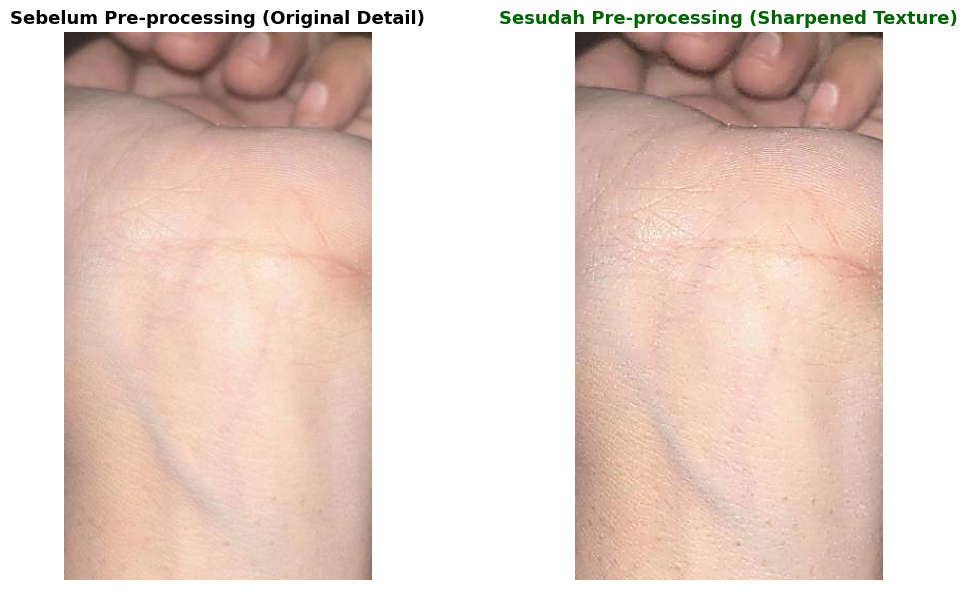

📸 Perbandingan visual disimpan di: /kaggle/working/sharpening_comparison.png


In [5]:
# ========================================================
# 5. VISUALISASI SEBELUM VS SESUDAH PENAJAMAN (PRE-PROCESSING)
# ========================================================
def visualize_sharpening_effect():
    sample_img_path = None
    for c in CLASS_NAMES:
        c_dir = os.path.join(TRAIN_DIR, c)
        if os.path.exists(c_dir):
            files = [f for f in os.listdir(c_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
            if files:
                sample_img_path = os.path.join(c_dir, files[0])
                break
                
    if not sample_img_path:
        print("⚠️ Gambar sampel tidak ditemukan untuk visualisasi.")
        return

    original_img = Image.open(sample_img_path).convert("RGB")
    sharpen_op = SkinSharpenTransform(radius=2, percent=140, threshold=3)
    sharpened_img = sharpen_op(original_img)
    
    # Crop bagian tengah untuk melihat detail tekstur
    w, h = original_img.size
    crop_box = (w // 4, h // 4, 3 * w // 4, 3 * h // 4)
    crop_orig = original_img.crop(crop_box)
    crop_sharp = sharpened_img.crop(crop_box)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(crop_orig)
    axes[0].set_title("Sebelum Pre-processing (Original Detail)", fontsize=13, fontweight='bold')
    axes[0].axis("off")

    axes[1].imshow(crop_sharp)
    axes[1].set_title("Sesudah Pre-processing (Sharpened Texture)", fontsize=13, fontweight='bold', color='darkgreen')
    axes[1].axis("off")

    plt.tight_layout()
    comp_path = os.path.join(OUTPUT_DIR, "sharpening_comparison.png")
    plt.savefig(comp_path, dpi=150)
    plt.show()
    print(f"📸 Perbandingan visual disimpan di: {comp_path}")

visualize_sharpening_effect()

In [6]:
# ========================================================
# 6. ARSITEKTUR PEMODELAN RESNET-50 (TRANSFER LEARNING)
# ========================================================
class SkinUndertoneResNet50(nn.Module):
    """
    Model Klasifikasi Skin Undertone berbasis ResNet-50 Pretrained.
    - Backbone: ResNet-50 ImageNet-1K
    - Fine-tuning: Pembekuan conv1, bn1, layer1, layer2; fine-tuning layer3 & layer4
    - Custom Head: Dropout -> Linear(2048 -> 512) -> BatchNorm -> ReLU -> Dropout -> Linear(512 -> 3)
    """
    def __init__(self, num_classes: int = 3, dropout_rate: float = 0.4, freeze_early_layers: bool = True):
        super().__init__()
        weights = models.ResNet50_Weights.DEFAULT
        self.resnet = models.resnet50(weights=weights)
        
        # Pembekuan layer awal untuk dataset kecil (~625 gambar train) guna mencegah overfitting
        if freeze_early_layers:
            for name, param in self.resnet.named_parameters():
                if any(x in name for x in ['conv1', 'bn1', 'layer1', 'layer2']):
                    param.requires_grad = False
                    
        # Rekonstruksi Classification Head
        in_features = self.resnet.fc.in_features  # 2048
        self.resnet.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate * 0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.resnet(x)

# Uji inisialisasi model
test_model = SkinUndertoneResNet50(num_classes=len(CLASS_NAMES), dropout_rate=DROPOUT_RATE).to(device)
total_params = sum(p.numel() for p in test_model.parameters())
trainable_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print(f"🏗️  Model ResNet-50 berhasil diinisialisasi:")
print(f"   Total Parameters     : {total_params:,}")
print(f"   Trainable Parameters : {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")
print(f"   Frozen Parameters    : {total_params - trainable_params:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


🏗️  Model ResNet-50 berhasil diinisialisasi:
   Total Parameters     : 24,559,683
   Trainable Parameters : 19,045,379 (77.5%)
   Frozen Parameters    : 5,514,304


In [7]:
# ========================================================
# 7. UTILITIES: MIXUP DATA & WARMUP COSINE SCHEDULER
# ========================================================
def mixup_data(x, y, alpha=0.2):
    """Menghasilkan kombinasi input dan target berbobot beta distribution."""
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

class WarmupCosineScheduler:
    """Learning rate scheduler dengan Linear Warmup dan Cosine Decay."""
    def __init__(self, optimizer, warmup_epochs, total_epochs, min_lr=1e-6):
        self.optimizer = optimizer
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        self.min_lr = min_lr
        self.base_lrs = [group['lr'] for group in optimizer.param_groups]

    def step(self, epoch):
        lrs = []
        for i, param_group in enumerate(self.optimizer.param_groups):
            base_lr = self.base_lrs[i]
            if epoch < self.warmup_epochs:
                lr = base_lr * (epoch + 1) / self.warmup_epochs
            else:
                progress = (epoch - self.warmup_epochs) / max(1, (self.total_epochs - self.warmup_epochs))
                lr = self.min_lr + (base_lr - self.min_lr) * 0.5 * (1 + math.cos(math.pi * progress))
            param_group['lr'] = lr
            lrs.append(lr)
        return lrs[0]

In [8]:
# ========================================================
# 8. TRAINING & VALIDATION PIPELINE
# ========================================================
def train_model():
    if not os.path.exists(TRAIN_DIR) or not os.path.exists(VALID_DIR):
        print("❌ Dataset tidak ditemukan. Periksa path folder train/valid.")
        return None

    # Load Dataset
    train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
    valid_dataset = datasets.ImageFolder(VALID_DIR, transform=eval_transforms)

    num_workers = 2 if torch.cuda.is_available() else 0
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=num_workers, pin_memory=torch.cuda.is_available(), drop_last=True
    )
    valid_loader = DataLoader(
        valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )

    # Hitung Bobot Kelas untuk mengatasi imbalance data train
    targets = train_dataset.targets
    class_counts = [targets.count(i) for i in range(len(CLASS_NAMES))]
    total_samples = sum(class_counts)
    class_weights = [total_samples / (len(CLASS_NAMES) * c) for c in class_counts]
    class_weights_tensor = torch.FloatTensor(class_weights).to(device)

    print("📊 Distribusi Kelas Train:")
    for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights):
        print(f"   - {name:<8}: {cnt:>3} gambar | Weight Loss: {w:.3f}")

    # Inisialisasi Model ResNet-50
    model = SkinUndertoneResNet50(num_classes=len(CLASS_NAMES), dropout_rate=DROPOUT_RATE).to(device)

    # Loss Function dengan Label Smoothing & Class Weighting
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=LABEL_SMOOTH)

    # Optimizer dengan Diferensiasi Learning Rate: Backbone vs Head
    backbone_params = []
    head_params = []
    for name, param in model.named_parameters():
        if param.requires_grad:
            if "fc" in name:
                head_params.append(param)
            else:
                backbone_params.append(param)

    optimizer = optim.AdamW([
        {"params": backbone_params, "lr": BACKBONE_LR},
        {"params": head_params, "lr": LEARNING_RATE}
    ], weight_decay=WEIGHT_DECAY, betas=(0.9, 0.999))

    scheduler = WarmupCosineScheduler(optimizer, warmup_epochs=WARMUP_EPOCHS, total_epochs=NUM_EPOCHS, min_lr=1e-6)

    # Metric History
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "learning_rates": []
    }

    best_val_acc = 0.0
    no_improve_count = 0
    start_time = time.time()

    print(f"\n🚀 Memulai Training ResNet-50 ({NUM_EPOCHS} Epochs)...\n" + "="*60)

    for epoch in range(NUM_EPOCHS):
        curr_lr = scheduler.step(epoch)
        history["learning_rates"].append(curr_lr)

        # --- TRAINING PHASE ---
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            use_mixup = (MIXUP_ALPHA > 0) and (random.random() > 0.4)

            if use_mixup:
                inputs, labels_a, labels_b, lam = mixup_data(inputs, labels, MIXUP_ALPHA)

            optimizer.zero_grad()
            outputs = model(inputs)

            if use_mixup:
                loss = mixup_criterion(criterion, outputs, labels_a, labels_b, lam)
            else:
                loss = criterion(outputs, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += (preds == labels).sum().item()
            train_total += inputs.size(0)

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = train_correct / train_total * 100

        # --- VALIDATION PHASE ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for inputs, labels in valid_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += inputs.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total * 100

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc)

        print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] "
              f"| Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.2f}% "
              f"| Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.2f}% "
              f"| LR: {curr_lr:.2e}")

        # Checkpoint Best Model
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            no_improve_count = 0
            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_acc": best_val_acc,
                "history": history
            }, MODEL_PATH)
            print(f"   ⭐ Model Terbaik Disimpan! (Val Acc: {best_val_acc:.2f}%)")
        else:
            no_improve_count += 1
            if no_improve_count >= PATIENCE:
                print(f"\n⏹️  Early Stopping dipicu pada Epoch {epoch+1} (Patience: {PATIENCE})")
                break

    elapsed = time.time() - start_time
    print(f"\n🏁 Training selesai dalam {elapsed//60:.0f}m {elapsed%60:.0f}s. Akurasi Val Terbaik: {best_val_acc:.2f}%")
    return history

In [9]:
# ========================================================
# 9. EVALUASI KOMPREHENSIF PADA TEST SET
# ========================================================
def evaluate_test_set():
    if not os.path.exists(TEST_DIR):
        print("\n⚠️ Folder test tidak ditemukan, melewati evaluasi test.")
        return None
    if not os.path.exists(MODEL_PATH):
        print("\n⚠️ File checkpoint model belum tersedia.")
        return None

    test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transforms)
    num_workers = 2 if torch.cuda.is_available() else 0
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available()
    )

    # Load Model Checkpoint Terbaik
    model = SkinUndertoneResNet50(num_classes=len(CLASS_NAMES), dropout_rate=DROPOUT_RATE).to(device)
    checkpoint = torch.load(MODEL_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    criterion = nn.CrossEntropyLoss()
    num_classes = len(CLASS_NAMES)

    test_loss = 0.0
    test_correct = 0
    test_total = 0
    confusion = [[0] * num_classes for _ in range(num_classes)]

    all_preds, all_labels = [], []

    print("\n--- Memulai Evaluasi Komprehensif Test Set ---")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)
            test_loss += loss.item() * inputs.size(0)
            test_correct += (preds == labels).sum().item()
            test_total += inputs.size(0)

            for t, p in zip(labels.cpu().numpy(), preds.cpu().numpy()):
                confusion[t][p] += 1
                all_labels.append(t)
                all_preds.append(p)

    test_acc = test_correct / test_total * 100

    # Perhitungan Metrik per Kelas & Macro Average
    precisions, recalls, f1s = [], [], []
    print(f"\n📋 Per-Class Performance:")
    for i in range(num_classes):
        tp = confusion[i][i]
        fp = sum(confusion[r][i] for r in range(num_classes)) - tp
        fn = sum(confusion[i][c] for c in range(num_classes)) - tp

        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0

        precisions.append(p)
        recalls.append(r)
        f1s.append(f1)
        print(f"   Kelas {CLASS_NAMES[i]:<8} | Precision: {p*100:>6.2f}% | Recall: {r*100:>6.2f}% | F1: {f1*100:>6.2f}%")

    macro_prec = sum(precisions) / num_classes * 100
    macro_rec  = sum(recalls) / num_classes * 100
    macro_f1   = sum(f1s) / num_classes * 100

    print("\n" + "="*45)
    print(f"🎯 Test Accuracy   : {test_acc:.2f}%")
    print(f"🎯 Macro Precision : {macro_prec:.2f}%")
    print(f"🎯 Macro Recall    : {macro_rec:.2f}%")
    print(f"🎯 Macro F1-Score  : {macro_f1:.2f}%")
    print("="*45)

    return {
        "accuracy": test_acc,
        "macro_precision": macro_prec,
        "macro_recall": macro_rec,
        "macro_f1": macro_f1,
        "confusion_matrix": confusion
    }

In [10]:
# ========================================================
# 10. VISUALISASI HASIL PELATIHAN (CURVE & CONFUSION MATRIX)
# ========================================================
def plot_training_results(history, confusion_matrix=None):
    if not history:
        return

    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Loss Curve
    axes[0].plot(epochs, history["train_loss"], 'o-', label="Train Loss", color="#1f77b4", linewidth=2)
    axes[0].plot(epochs, history["val_loss"], 's-', label="Validation Loss", color="#ff7f0e", linewidth=2)
    axes[0].set_title("Training & Validation Loss", fontsize=13, fontweight='bold')
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].legend()

    # Plot Accuracy Curve
    axes[1].plot(epochs, history["train_acc"], 'o-', label="Train Accuracy", color="#2ca02c", linewidth=2)
    axes[1].plot(epochs, history["val_acc"], 's-', label="Validation Accuracy", color="#d62728", linewidth=2)
    axes[1].set_title("Training & Validation Accuracy (%)", fontsize=13, fontweight='bold')
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].grid(True, linestyle="--", alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    curve_path = os.path.join(OUTPUT_DIR, "training_curves_resnet50.png")
    plt.savefig(curve_path, dpi=150)
    plt.show()
    print(f"📈 Grafik kurva pelatihan disimpan di: {curve_path}")

    # Plot Confusion Matrix jika tersedia
    if confusion_matrix is not None:
        cm = np.array(confusion_matrix)
        plt.figure(figsize=(6, 5))
        plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
        plt.title("Confusion Matrix - Test Set", fontsize=13, fontweight='bold')
        plt.colorbar()
        tick_marks = np.arange(len(CLASS_NAMES))
        plt.xticks(tick_marks, CLASS_NAMES, rotation=45)
        plt.yticks(tick_marks, CLASS_NAMES)

        thresh = cm.max() / 2.
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                plt.text(j, i, format(cm[i, j], 'd'),
                         horizontalalignment="center",
                         color="white" if cm[i, j] > thresh else "black",
                         fontweight="bold")

        plt.ylabel("True Label")
        plt.xlabel("Predicted Label")
        plt.tight_layout()
        cm_path = os.path.join(OUTPUT_DIR, "confusion_matrix_resnet50.png")
        plt.savefig(cm_path, dpi=150)
        plt.show()
        print(f"📊 Confusion Matrix disimpan di: {cm_path}")

🏁 MULAI EKSEKUSI PIPELINE RESNET-50
📊 Distribusi Kelas Train:
   - cool    : 173 gambar | Weight Loss: 1.204
   - neutral : 255 gambar | Weight Loss: 0.817
   - warm    : 197 gambar | Weight Loss: 1.058

🚀 Memulai Training ResNet-50 (60 Epochs)...
Epoch [01/60] | Train Loss: 1.1220 Acc: 39.42% | Val Loss: 1.1069 Acc: 37.91% | LR: 8.00e-06
   ⭐ Model Terbaik Disimpan! (Val Acc: 37.91%)
Epoch [02/60] | Train Loss: 1.1110 Acc: 35.90% | Val Loss: 1.1451 Acc: 32.03% | LR: 1.60e-05
Epoch [03/60] | Train Loss: 1.0731 Acc: 40.38% | Val Loss: 1.1382 Acc: 32.03% | LR: 2.40e-05
Epoch [04/60] | Train Loss: 1.0563 Acc: 42.95% | Val Loss: 1.1920 Acc: 36.60% | LR: 3.20e-05
Epoch [05/60] | Train Loss: 1.0439 Acc: 43.43% | Val Loss: 1.1432 Acc: 37.25% | LR: 4.00e-05
Epoch [06/60] | Train Loss: 1.0243 Acc: 49.04% | Val Loss: 1.1276 Acc: 36.60% | LR: 4.00e-05
Epoch [07/60] | Train Loss: 0.9724 Acc: 53.85% | Val Loss: 1.1278 Acc: 39.87% | LR: 4.00e-05
   ⭐ Model Terbaik Disimpan! (Val Acc: 39.87%)
Epoch [

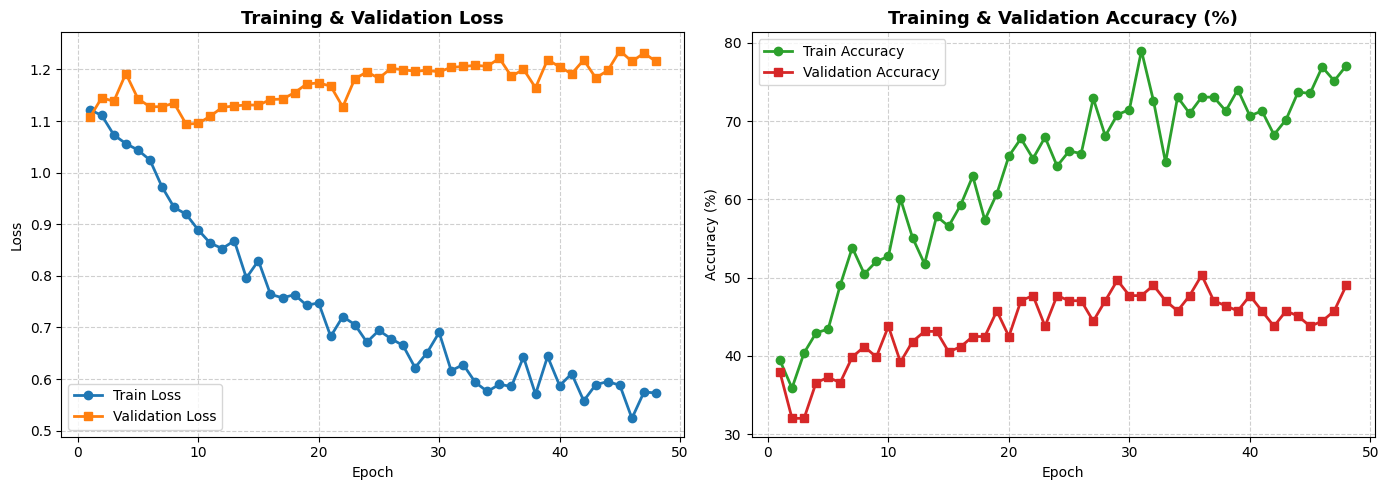

📈 Grafik kurva pelatihan disimpan di: /kaggle/working/training_curves_resnet50.png


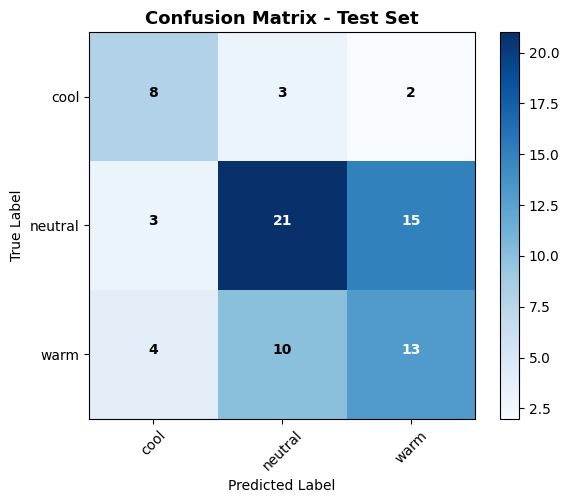

📊 Confusion Matrix disimpan di: /kaggle/working/confusion_matrix_resnet50.png

===REGISTRY_PAYLOAD_START===
{
  "topic": "topic-b",
  "model": "ResNet-50",
  "objective": "Klasifikasi Skin Undertone dengan Pre-processing Penajaman (Unsharp Mask) dan ResNet-50 Fine-Tuning",
  "dataset": "skin-undertone",
  "owner": "Egyanta Bareka Sebayang",
  "metrics": {
    "accuracy": 53.16455696202531,
    "f1": 53.43037960197298,
    "precision": 52.81045751633987,
    "recall": 54.510921177587846
  }
}
===REGISTRY_PAYLOAD_END===


In [11]:
# ========================================================
# 11. EKSEKUSI UTAMA (MAIN TRAINING & REGISTRY LOGGING)
# ========================================================
if __name__ == "__main__":
    print("==========================================")
    print("🏁 MULAI EKSEKUSI PIPELINE RESNET-50")
    print("==========================================")

    # 1. Jalankan Training
    history = train_model()

    # 2. Jalankan Evaluasi Test Set
    final_metrics = evaluate_test_set()

    # 3. Tampilkan Visualisasi Kurva & Confusion Matrix
    if history and final_metrics:
        plot_training_results(history, final_metrics.get("confusion_matrix"))

    # 4. Registrasi Eksperimen Otomatis
    if final_metrics:
        # Deklarasikan variabel numerik di scope globals()
        accuracy  = final_metrics["accuracy"]
        f1_score  = final_metrics["macro_f1"]
        precision = final_metrics["macro_precision"]
        recall    = final_metrics["macro_recall"]

        auto_log_experiment(
            env_globals=globals(),
            topic="topic-b",
            model="ResNet-50",
            objective="Klasifikasi Skin Undertone dengan Pre-processing Penajaman (Unsharp Mask) dan ResNet-50 Fine-Tuning",
            dataset="skin-undertone",
            owner="Egyanta Bareka Sebayang"
        )